# Лабораторная работа №1.1
## Предобработка данных для обучения нейронных сетей

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [45]:
# Загружаем набор данных Iris
# Параметр as_frame=True позволяет получить данные в формате pandas DataFrame
iris = load_iris(as_frame=True)

# Получаем таблицу с входными признаками объектов
X = iris.data

# Получаем целевую переменную, содержащую классы цветков Iris
y = iris.target

# Выводим сообщение, подтверждающее успешную загрузку данных
print("Набор данных Iris успешно загружен.")

Набор данных Iris успешно загружен.


### 2. Изучение структуры набора данных

In [46]:
# Выводим общую информацию о структуре набора данных Iris
print("СТРУКТУРА НАБОРА ДАННЫХ IRIS")

# Определяем количество объектов в наборе данных
# X.shape[0] возвращает количество строк таблицы
print("Количество объектов:", X.shape[0])

# Определяем количество входных признаков
# X.shape[1] возвращает количество столбцов таблицы
print("Количество признаков:", X.shape[1])

# Выводим размерность таблицы входных данных
# Результат представлен в виде: (количество строк, количество столбцов)
print("Размерность таблицы признаков:", X.shape)

# Выводим названия всех входных признаков
print("\nНазвания признаков:")
for number, feature_name in enumerate(X.columns, start=1):
    # Выводим порядковый номер и название каждого признака
    print(f"{number}. {feature_name}")

# Выводим названия классов целевой переменной
print("\nКлассы целевой переменной:")
for class_number, class_name in enumerate(iris.target_names):
    # Выводим числовой код класса и соответствующее ему название
    print(f"{class_number} — {class_name}")

СТРУКТУРА НАБОРА ДАННЫХ IRIS
Количество объектов: 150
Количество признаков: 4
Размерность таблицы признаков: (150, 4)

Названия признаков:
1. sepal length (cm)
2. sepal width (cm)
3. petal length (cm)
4. petal width (cm)

Классы целевой переменной:
0 — setosa
1 — versicolor
2 — virginica


### 3. Просмотр данных и определение типов признаков 

In [47]:
# Выводим первые пять строк таблицы входных признаков
# Метод head() позволяет быстро просмотреть структуру и значения данных
print("ПЕРВЫЕ 5 СТРОК ВХОДНЫХ ДАННЫХ:")
print(X.head())

# Выводим тип данных каждого входного признака
# Атрибут dtypes показывает тип данных для каждого столбца DataFrame
print("\nТИПЫ ВХОДНЫХ ПРИЗНАКОВ:")
print(X.dtypes)

# Выводим тип данных целевой переменной
print("\nТИП ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:")
print(y.dtype)

# Выводим первые пять значений целевой переменной
# Это позволяет увидеть числовое представление классов
print("\nПЕРВЫЕ 5 ЗНАЧЕНИЙ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:")
print(y.head())

ПЕРВЫЕ 5 СТРОК ВХОДНЫХ ДАННЫХ:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

ТИПЫ ВХОДНЫХ ПРИЗНАКОВ:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

ТИП ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:
int64

ПЕРВЫЕ 5 ЗНАЧЕНИЙ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


### 4. Анализ пропущенных значений

In [48]:
# Проверяем наличие пропущенных значений в каждом входном признаке
# Метод isnull() определяет пропущенные значения,
# а метод sum() подсчитывает их количество в каждом столбце
missing_values_X = X.isnull().sum()
print("КОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ ВО ВХОДНЫХ ПРИЗНАКАХ:")
print(missing_values_X)

# Проверяем количество пропущенных значений в целевой переменной
missing_values_y = y.isnull().sum()
print("\nКОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ В ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:")
print(missing_values_y)

# Подсчитываем общее количество пропущенных значений
# во всех входных признаках и целевой переменной
total_missing_values = missing_values_X.sum() + missing_values_y

print("\nОБЩЕЕ КОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ:")
print(total_missing_values)

КОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ ВО ВХОДНЫХ ПРИЗНАКАХ:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

КОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ В ЦЕЛЕВОЙ ПЕРЕМЕННОЙ:
0

ОБЩЕЕ КОЛИЧЕСТВО ПРОПУЩЕННЫХ ЗНАЧЕНИЙ:
0


### 5. Визуализация распределения признаков

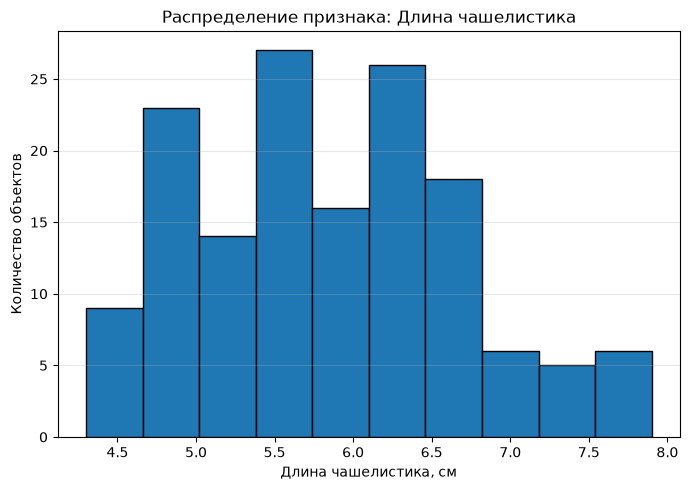

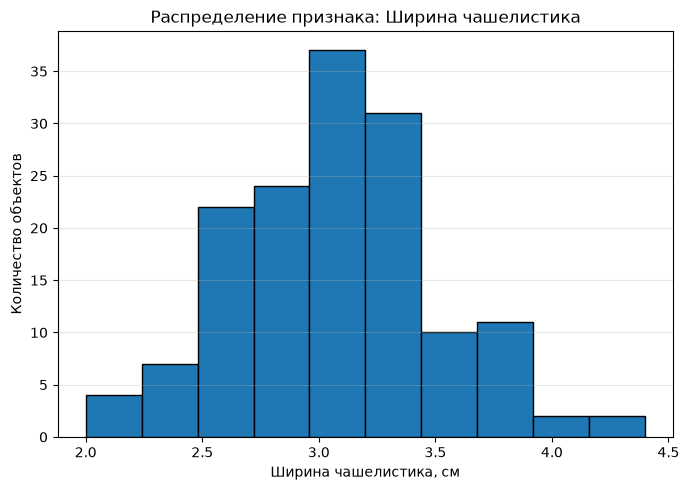

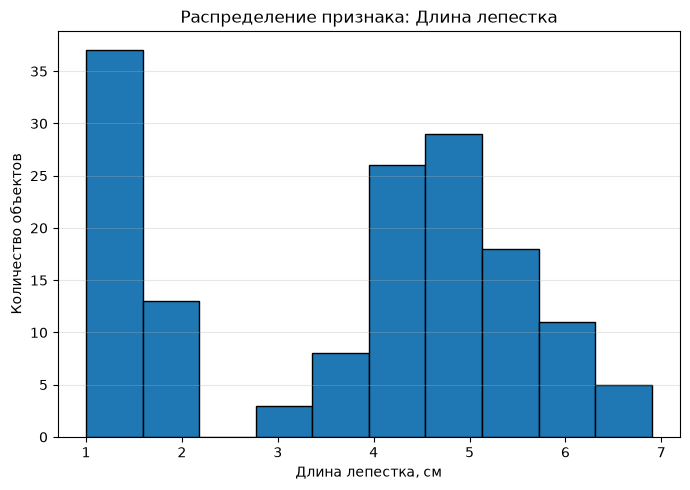

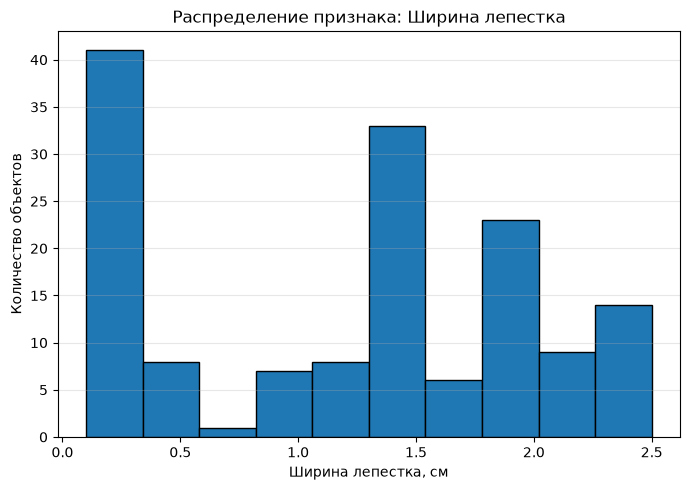

In [49]:
# Ключи соответствуют исходным названиям столбцов в наборе данных Iris
feature_names_ru = {
    "sepal length (cm)": "Длина чашелистика",
    "sepal width (cm)": "Ширина чашелистика",
    "petal length (cm)": "Длина лепестка",
    "petal width (cm)": "Ширина лепестка"
}

# Последовательно строим гистограмму для каждого входного признака
for feature in X.columns:
    plt.figure(figsize=(7, 5))
    plt.hist(X[feature], bins=10, edgecolor="black")
    plt.title(f"Распределение признака: {feature_names_ru[feature]}")
    plt.xlabel(f"{feature_names_ru[feature]}, см")
    plt.ylabel("Количество объектов")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 6. Обнаружение выбросов методом IQR

In [50]:
# Создаем пустой словарь для хранения информации о выбросах
# для каждого числового признака
outliers_info = {}

# Последовательно анализируем каждый входной признак
for feature in X.columns:

    # Вычисляем первый квартиль Q1 (25-й процентиль)
    Q1 = X[feature].quantile(0.25)

    # Вычисляем третий квартиль Q3 (75-й процентиль)
    Q3 = X[feature].quantile(0.75)

    # Вычисляем межквартильный размах
    IQR = Q3 - Q1

    # Определяем нижнюю границу допустимых значений
    lower_bound = Q1 - 1.5 * IQR

    # Определяем верхнюю границу допустимых значений
    upper_bound = Q3 + 1.5 * IQR

    # Находим значения, которые выходят за рассчитанные границы
    outliers = X[
        (X[feature] < lower_bound) |
        (X[feature] > upper_bound)
    ][feature]

    # Сохраняем количество найденных выбросов
    # для дальнейшего анализа
    outliers_info[feature] = len(outliers)

    # Выводим название
    print(f"\nПРИЗНАК: {feature_names_ru[feature]}")

    # Выводим рассчитанные статистические показатели
    print(f"Q1: {Q1:.3f}")
    print(f"Q3: {Q3:.3f}")
    print(f"IQR: {IQR:.3f}")
    print(f"Нижняя граница: {lower_bound:.3f}")
    print(f"Верхняя граница: {upper_bound:.3f}")

    print(f"Количество потенциальных выбросов: {len(outliers)}")

    # Проверяем, были ли обнаружены выбросы
    if len(outliers) > 0:
        # Если выбросы обнаружены, выводим их значения
        print("Значения потенциальных выбросов:")
        print(outliers.to_list())
    else:
        print("Потенциальные выбросы не обнаружены.")


ПРИЗНАК: Длина чашелистика
Q1: 5.100
Q3: 6.400
IQR: 1.300
Нижняя граница: 3.150
Верхняя граница: 8.350
Количество потенциальных выбросов: 0
Потенциальные выбросы не обнаружены.

ПРИЗНАК: Ширина чашелистика
Q1: 2.800
Q3: 3.300
IQR: 0.500
Нижняя граница: 2.050
Верхняя граница: 4.050
Количество потенциальных выбросов: 4
Значения потенциальных выбросов:
[4.4, 4.1, 4.2, 2.0]

ПРИЗНАК: Длина лепестка
Q1: 1.600
Q3: 5.100
IQR: 3.500
Нижняя граница: -3.650
Верхняя граница: 10.350
Количество потенциальных выбросов: 0
Потенциальные выбросы не обнаружены.

ПРИЗНАК: Ширина лепестка
Q1: 0.300
Q3: 1.800
IQR: 1.500
Нижняя граница: -1.950
Верхняя граница: 4.050
Количество потенциальных выбросов: 0
Потенциальные выбросы не обнаружены.


### 7. Обработка выбросов
Для обработки обнаруженных выбросов используется замена медианным
значением признака.

In [51]:
# Это позволяет сохранить исходный набор данных без изменений
X_processed = X.copy()
print("Количество объектов до обработки:", X_processed.shape[0])

Количество объектов до обработки: 150


In [ ]:
# Последовательно обрабатываем каждый числовой входной признак
for feature in X_processed.columns:

    # Вычисляем первый квартиль Q1
    Q1 = X_processed[feature].quantile(0.25)

    # Вычисляем третий квартиль Q3
    Q3 = X_processed[feature].quantile(0.75)

    # Вычисляем межквартильный размах IQR
    IQR = Q3 - Q1

    # Вычисляем нижнюю границу для определения выбросов
    lower_bound = Q1 - 1.5 * IQR

    # Вычисляем верхнюю границу для определения выбросов
    upper_bound = Q3 + 1.5 * IQR

    # Создаем логическую маску для потенциальных выбросов
    outlier_mask = (
        (X_processed[feature] < lower_bound) |
        (X_processed[feature] > upper_bound)
    )

    # Подсчитываем количество обнаруженных выбросов
    outlier_count = outlier_mask.sum()

    # Вычисляем медиану текущего признака
    median_value = X_processed[feature].median()

    # Выводим название текущего признака
    print(f"\nПРИЗНАК: {feature_names_ru[feature]}")

    # Выводим количество значений, которые необходимо обработать
    print(f"Количество выбросов до обработки: {outlier_count}")

    # Проверяем наличие выбросов
    if outlier_count > 0:

        # Выводим медианное значение, используемое для замены
        print(f"Медиана признака: {median_value:.3f}")

        # Выводим значения выбросов до их замены
        print("Значения выбросов до замены:")
        print(X_processed.loc[outlier_mask, feature].to_list())

        # Заменяем обнаруженные выбросы медианным значением
        X_processed.loc[outlier_mask, feature] = median_value

        # Выводим сообщение об успешной замене
        print("Выбросы заменены медианным значением\n")

    else:

        # Если выбросы отсутствуют, данные признака не изменяются
        print("Обработка не требуется")


ПРИЗНАК: Длина чашелистика
Количество выбросов до обработки: 0
Обработка не требуется

ПРИЗНАК: Ширина чашелистика
Количество выбросов до обработки: 4
Медиана признака: 3.000
Значения выбросов до замены:
[4.4, 4.1, 4.2, 2.0]
Выбросы заменены медианным значением

ПРИЗНАК: Длина лепестка
Количество выбросов до обработки: 0
Обработка не требуется

ПРИЗНАК: Ширина лепестка
Количество выбросов до обработки: 0
Обработка не требуется


### Проверка результатов обработки выбросов

In [53]:
# Повторно проверяем каждый признак после обработки выбросов
for feature in X_processed.columns:
    Q1 = X_processed[feature].quantile(0.25)
    Q3 = X_processed[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Находим значения, которые после обработки остаются за границами IQR
    outlier_mask = (
        (X_processed[feature] < lower_bound) |
        (X_processed[feature] > upper_bound)
    )

    # Подсчитываем количество выбросов после обработки
    outlier_count = outlier_mask.sum()

    print(f"\nПРИЗНАК: {feature_names_ru[feature]}")
    print(f"Количество выбросов после обработки: {outlier_count}")

print(f"\nКоличество объектов после обработки: {len(X_processed)}")


ПРИЗНАК: Длина чашелистика
Количество выбросов после обработки: 0

ПРИЗНАК: Ширина чашелистика
Количество выбросов после обработки: 0

ПРИЗНАК: Длина лепестка
Количество выбросов после обработки: 0

ПРИЗНАК: Ширина лепестка
Количество выбросов после обработки: 0

Количество объектов после обработки: 150


### 8. Работа с категориальными признаками

In [54]:
# Выводим тип данных каждого входного признака
print("ТИПЫ ВХОДНЫХ ПРИЗНАКОВ:")
print(X_processed.dtypes)

# Выбираем категориальные признаки по типу данных
categorical_features = X_processed.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Выводим результат проверки
print("\nКАТЕГОРИАЛЬНЫЕ ВХОДНЫЕ ПРИЗНАКИ:")

if len(categorical_features) > 0:
    print(categorical_features)
    print(f"Количество категориальных признаков: {len(categorical_features)}")
else:
    print("Категориальные входные признаки отсутствуют.")
    print("Кодирование входных признаков не требуется.")

# Отдельно выводим информацию о целевой переменной
# Целевая переменная не является входным признаком
print("\nЦЕЛЕВАЯ ПЕРЕМЕННАЯ:")
print(f"Название: {y.name}")
print(f"Тип данных: {y.dtype}")
print(f"Уникальные значения: {sorted(y.unique().tolist())}")

ТИПЫ ВХОДНЫХ ПРИЗНАКОВ:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

КАТЕГОРИАЛЬНЫЕ ВХОДНЫЕ ПРИЗНАКИ:
Категориальные входные признаки отсутствуют.
Кодирование входных признаков не требуется.

ЦЕЛЕВАЯ ПЕРЕМЕННАЯ:
Название: target
Тип данных: int64
Уникальные значения: [0, 1, 2]


### 9. Разделение данных

Обработанный набор данных разделяется на обучающую, валидационную
и тестовую выборки в соотношении приблизительно 70:15:15.

При разделении используется стратификация по целевой переменной
для сохранения соотношения классов.

In [58]:
# Разделяем обработанные данные:
# 70% — обучающая выборка
# 30% — временная выборка
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_processed,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Делим оставшиеся 30% поровну:
# 15% — валидационная выборка
# 15% — тестовая выборка
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Выводим размеры полученных выборок
print("РАЗМЕРЫ ВЫБОРОК:")
print(f"Обучающая выборка: {X_train_raw.shape}")
print(f"Валидационная выборка: {X_val_raw.shape}")
print(f"Тестовая выборка: {X_test_raw.shape}")

# Проверяем распределение классов
print("\nРАСПРЕДЕЛЕНИЕ КЛАССОВ:")

print("Обучающая выборка:")
print(y_train.value_counts().sort_index())

print("\nВалидационная выборка:")
print(y_val.value_counts().sort_index())

print("\nТестовая выборка:")
print(y_test.value_counts().sort_index(),)

# Проверяем общее количество объектов
total_objects = len(X_train_raw) + len(X_val_raw) + len(X_test_raw)

print("\nОБЩЕЕ КОЛИЧЕСТВО ОБЪЕКТОВ:")
print(total_objects)

РАЗМЕРЫ ВЫБОРОК:
Обучающая выборка: (105, 4)
Валидационная выборка: (22, 4)
Тестовая выборка: (23, 4)

РАСПРЕДЕЛЕНИЕ КЛАССОВ:
Обучающая выборка:
target
0    35
1    35
2    35
Name: count, dtype: int64

Валидационная выборка:
target
0    8
1    7
2    7
Name: count, dtype: int64

Тестовая выборка:
target
0    7
1    8
2    8
Name: count, dtype: int64

ОБЩЕЕ КОЛИЧЕСТВО ОБЪЕКТОВ:
150


### 10. Масштабирование числовых признаков

Для масштабирования числовых признаков используется стандартизация.

Параметры стандартизации вычисляются по обучающей выборке.
После этого те же параметры применяются к обучающей,
валидационной и тестовой выборкам.

In [56]:
# Создаем объект стандартизации
scaler = StandardScaler()

# Вычисляем параметры стандартизации
# только по обучающей выборке
scaler.fit(X_train_raw)

# Применяем одинаковое преобразование
# ко всем трем выборкам
X_train_scaled_array = scaler.transform(X_train_raw)
X_val_scaled_array = scaler.transform(X_val_raw)
X_test_scaled_array = scaler.transform(X_test_raw)

# Преобразуем результаты обратно в DataFrame
X_train = X_train_raw.copy()
X_train[X_train_raw.columns] = X_train_scaled_array

X_val = X_val_raw.copy()
X_val[X_val_raw.columns] = X_val_scaled_array

X_test = X_test_raw.copy()
X_test[X_test_raw.columns] = X_test_scaled_array

# Проверяем результат стандартизации обучающей выборки
print("ОБУЧАЮЩАЯ ВЫБОРКА ПОСЛЕ СТАНДАРТИЗАЦИИ:")

print("\nСредние значения:")
print(X_train.mean())

print("\nСтандартные отклонения:")
print(X_train.std(ddof=0))

# Проверяем размеры выборок после стандартизации
print("\nРАЗМЕРЫ ВЫБОРОК ПОСЛЕ СТАНДАРТИЗАЦИИ:")
print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")

ОБУЧАЮЩАЯ ВЫБОРКА ПОСЛЕ СТАНДАРТИЗАЦИИ:

Средние значения:
sepal length (cm)    3.002889e-16
sepal width (cm)    -1.089076e-15
petal length (cm)   -1.395709e-16
petal width (cm)    -5.286776e-17
dtype: float64

Стандартные отклонения:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64

РАЗМЕРЫ ВЫБОРОК ПОСЛЕ СТАНДАРТИЗАЦИИ:
X_train: (105, 4)
X_val:   (22, 4)
X_test:  (23, 4)
